# **Modelling the three body problem**
ESA colleagues can model coplanar systems up to three stars.
#**Few tips**


*   Run all the cells from the top
*   Build a starsystem using the two objects, Star and StarSystem , or use the make_figure_eight().
*   Call the solve_steller_motion() and plotting_orbits().








In [12]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

MAXIMUM_STARS = 3
MINIMUM_SEPARATION = 1e-3 # integration stops when two stars get this close
FIGURE_EIGHT_PERIOD = 6.32591398 # period of the Chenciner-Montgomery orbit, I found this 



# A container for a star.

In [13]:
# a star object in x-y plane
class Star:
    def __init__(self, x, y, vel_x, vel_y, mass=1.0, name="star"):
        assert np.all(np.isfinite([x, y, vel_x, vel_y])), "values hav to be finite"
        assert mass > 0.0, "mass has a positive value because negative mass doesn't make sense "
        self.x = float(x)
        self.y = float(y)
        self.vel_x = float(vel_x)
        self.vel_y = float(vel_y)
        self.mass = float(mass)
        self.name = name

# Fourth order Runge-Kutta , returning times and states.

In [14]:
def rk4_integrate(dydt, y_initial, max_time, n_steps):

    #4th order Runge-Kutta, returns times and states (4N, n+1).
    assert n_steps >= 1 and max_time > 0.0, "must have at least one step and time should be positive"
    delta_t = max_time / n_steps # every iteration advances by delta_t time"
    t_values = np.linspace(0.0, max_time, n_steps + 1)
    states = np.zeros((len(y_initial), n_steps + 1))
    states[:, 0] = y_initial

    for step in range(n_steps):
        curr_time, curr_state = t_values[step], states[:, step]
        k1 = dydt(curr_time, curr_state)
        k2 = dydt(curr_time + 0.5 * delta_t, curr_state + 0.5 * delta_t * k1)
        k3 = dydt(curr_time + 0.5 * delta_t, curr_state + 0.5 * delta_t * k2)
        k4 = dydt(curr_time + delta_t, curr_state + delta_t * k3)
        states[:, step + 1] = curr_state + delta_t * (k1 + 2*k2 + 2*k3 + k4) / 6.0

    return t_values, states

# StarSystem,Equations and Solvers

In [15]:
class StarSystem:
  #Maximium of three stars interacting through Newtonian gravity

    def __init__(self, lam=0.0):
        assert 0 <= lam < 1, "Lambda must be 0 or less than 1 "
        self.lam = lam
        self.stars = [] # this lists the stars
        self.t_solution = None
        self.y_solution = None

    @property
    def N_stars(self):
        return len(self.stars)

    @property
    def is_defined(self):
        return self.N_stars >= 2
    @property
    def masses(self):
      # array of all star masses
        return np.array([star.mass for star in self.stars])

    def add_star(self, star):
        assert len(self.stars) < 3, "Add 3 stars Maximum"
        self.stars.append(star)

    def initial_state(self):
        assert self.is_defined, "system needs at least two stars"
        return np.array([[star.x for star in self.stars],
                         [star.y for star in self.stars],
                         [star.vel_x for star in self.stars],
                         [star.vel_y for star in self.stars]]).flatten()


    # equations of motion as modifications to gravity
    def calculate_stellar_system_dydt(self, time, state):
      #
        star_num = len(self.stars)
        masses = np.array([s.mass for s in self.stars])
        x, y, vel_x, vel_y = np.reshape(state, (4, star_num))
        gap_x = x[None, :] - x[:, None] # velocity differnces x and y(below)
        gap_y = y[None, :] - y[:, None]
        relative_vel_x = vel_x[None, :] - vel_x[:, None]
        relative_vel_y = vel_y[None, :] - vel_y[:, None]

        r_squared = gap_x**2 + gap_y**2 # calculates distance of pairs
        np.fill_diagonal(r_squared, 1.0)

        angular_mom_term = relative_vel_y * gap_x - relative_vel_x * gap_y
       #introduces a modification to the gravitational model
        gen_relativity = 1 + 3 * self.lam**2 * angular_mom_term**2 / r_squared
        pull = gen_relativity * masses[None, :] / r_squared**1.5
        np.fill_diagonal(pull, 0.0)

        ax = np.sum(pull * gap_x, axis=1)# calcultes acceleration of stars including the line below
        ay = np.sum(pull * gap_y, axis=1)
        return np.concatenate([vel_x, vel_y, ax, ay])

     # The below method solves the motion of the stars using ODEs
    def solve_stellar_motion(self, max_time=50.0, tolerance=1e-10,
                             n_steps=1000,
                             min_separation=MINIMUM_SEPARATION):
        assert self.is_defined, "need at least 2 stars"
        assert max_time > 0.0 and n_steps >= 2, "need max_time>0, n_steps>=2"
        assert 1e-14 <= tolerance <= 1e-3, "tolerance must be in the range of 1e-14 and 1e-3"
        initial_state = self.initial_state() # uses def initial state to start 4N numbers
        # does not start if two stars are on top of each other, takes in miminum separation
        assert self.calculate_pair_separations(initial_state).min() > \
            min_separation, "stars start closer than min_separation"

        def close_encounter(time, state):
            return self.calculate_pair_separations(state).min() - min_separation
        close_encounter.terminal = True

        t_requested = np.linspace(0.0, max_time, n_steps + 1)
        solution = solve_ivp(self.calculate_stellar_system_dydt,
                             [0.0, max_time], initial_state, method="DOP853",
                             t_eval=t_requested, rtol=tolerance,
                             atol=tolerance, events=close_encounter)
        t_values, y_values = solution.t, solution.y
        if solution.status == 1:   # keep the encounter itself in the output
            t_values = np.append(t_values, solution.t_events[0][0])
            y_values = np.column_stack([y_values, solution.y_events[0][0]])
            warnings.warn(f"Close encounter (< {min_separation}) at "
                          f"t = {t_values[-1]:.3f}; stopped early.")
        elif solution.status == -1:
            warnings.warn(f"Solver failed: {solution.message}")
        self.t_solution, self.y_solution = t_values, y_values
        return self.t_solution, self.y_solution

    def solve_stellar_motion_rk4(self, max_time, n_steps):
        '''Fixed-step RK4 version, used as an independent cross-check.'''
        assert self.is_defined, "System has not been fully defined"
        return rk4_integrate(self.calculate_stellar_system_dydt,
                             self.initial_state(), max_time, n_steps)

# ---- diagnostics (accept one state (4N,) or many (4N, n_times)) ------
    def split_state(self, state):
        #Return x, y, vx, vy, each of shape
        return np.reshape(state, (4, self.N_stars, -1))

    def calculate_pair_separations(self, state):
        #Separation of every pair of stars, shape (n_pairs and n_times).'''
        x, y, _, _ = self.split_state(state)
        i_index, j_index = np.triu_indices(self.N_stars, k=1)
        return np.hypot(x[i_index] - x[j_index], y[i_index] - y[j_index])

    def calculate_total_energy(self, state):
        #Newtonian kinetic + potential energy (conserved only if alpha=0).'''
        _, _, vx, vy = self.split_state(state)
        kinetic = 0.5 * np.sum(self.masses[:, None] * (vx**2 + vy**2), axis=0)
        i_index, j_index = np.triu_indices(self.N_stars, k=1)
        mass_products = self.masses[i_index] * self.masses[j_index]
        potential = -np.sum(mass_products[:, None] /
                            self.calculate_pair_separations(state), axis=0)
        return kinetic + potential

    def calculate_total_momentum(self, state):
        #Magnitude of the total linear momentum.'''
        _, _, vx, vy = self.split_state(state)
        px = np.sum(self.masses[:, None] * vx, axis=0)
        py = np.sum(self.masses[:, None] * vy, axis=0)
        return np.hypot(px, py)


        #plotting the orbits 
    def plot_the_orbits(self, ax=None, title=None, legend=True):
        """Plot the stored orbits; dots mark the final positions."""
        assert self.y_solution is not None, "call solve_stellar_motion first"
        if ax is None:                       # no axis given: make a new figure
            _, ax = plt.subplots(figsize=(6, 5))
        ax.grid(True)
        ax.set_xlabel("x", fontsize=12)
        ax.set_ylabel("y", fontsize=12)
        ax.set_aspect("equal", adjustable="datalim")
        ax.set_title(title or "")
        for istar in range(self.N_stars):
            x = self.y_solution[istar]
            y = self.y_solution[istar + self.N_stars]
            line, = ax.plot(x, y, "--", label=self.stars[istar].name)
            ax.plot(x[-1], y[-1], "o", color=line.get_color())
        if legend:
            ax.legend(loc="upper right", fontsize=8)

# The figure eight orbit

**Below is the method to build the three star orbit(Chencier and Montgomery),default value produce stable orbit**

In [16]:
def make_figure_eight(velocity_scale=1.0, x_shift=0.0, lam=0.0):
    #Figure-eight system; the defaults give the stable orbit.
    x1, y1 = 0.97000436, -0.24308753
    vx3, vy3 = -0.93240737 * velocity_scale, -0.86473146 * velocity_scale
    system = StarSystem(lam=lam)
    # equal masses: stars 0 and 1 move with -v/2 so net momentum is zero
    system.add_star(Star(x1 + x_shift, y1, -vx3 / 2, -vy3 / 2, 1.0, "star 0"))
    system.add_star(Star(-x1, -y1, -vx3 / 2, -vy3 / 2, 1.0, "star 1"))
    system.add_star(Star(0.0, 0.0, vx3, vy3, 1.0, "star 2"))
    return system

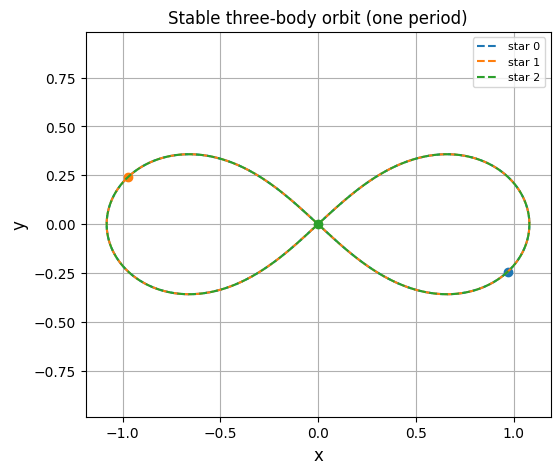

In [17]:
figure_eight = make_figure_eight()
figure_eight.solve_stellar_motion(FIGURE_EIGHT_PERIOD)
figure_eight.plot_the_orbits(title="Stable three-body orbit (one period)")
plt.savefig("fig_1.png", dpi=150, bbox_inches="tight")
plt.show()

# Tests
**Giving bad inputs to the break and test.**

In [18]:

def build_circular_binary(lam=0.0):
    #Two unit masses on a circular orbit of radius 1 (period 4 pi).
    system = StarSystem(lam=lam)
    system.add_star(Star(-1.0, 0.0, 0.0, -0.5, 1.0, "a"))
    system.add_star(Star(1.0, 0.0, 0.0, 0.5, 1.0, "b"))
    return system


def expect_assertion_error(function, *args, **kwargs):
    #True if calling function(...) raises an AssertionError.
    try:
        function(*args, **kwargs)
    except AssertionError:
        return True
    return False


def run_all_tests():

    # 1.two unit masses 2 apart attract with a = M / r^2 = 1/4( Newton's)
    binary = build_circular_binary()
    acceleration = binary.calculate_stellar_system_dydt(
        0.0, binary.initial_state())
    assert np.allclose(acceleration[4:6], [0.25, -0.25]), "Newton force wrong"
    print("test 1 is passed ")

    # 2. Modified gravity: circular binary has L^2/r^2 = v_rel^2 = 1, so the
    #    pull must be larger by exactly 1 + 3 lamda^2
    lam = 0.3
    modified = build_circular_binary(lam)
    acc_mod = modified.calculate_stellar_system_dydt(0.0, modified.initial_state())
    assert np.isclose(acc_mod[4], 0.25 * (1 + 3 * lam**2)), "general relativty factor wrong"
    print("test 2 is passed ")

    # 3. Newton's 3rd law, the two forces are equal and opposite
    for lam in (0.0, 0.4):
        system = StarSystem(lam=lam)
        system.add_star(Star(0.0, 0.0, 0.0, 0.0, mass=1.0))
        system.add_star(Star(2.0, 0.0, 0.0, 1.0, mass=3.0))  
        dydt = system.calculate_stellar_system_dydt(0.0, system.initial_state())
        acc_x = dydt[4:6]               # x-accelerations of star 0 and star 1
        force_0 = 1.0 * acc_x[0]        # force is mass * acceleration
        force_1 = 3.0 * acc_x[1]
        assert np.isclose(force_0 + force_1, 0.0), "Newtons 3rd law is broken"
    print("test 3 passed")

    # 4. circular binary returns to its start after one period, radius fixed
    binary.solve_stellar_motion(4 * np.pi, tolerance=1e-12)
    assert np.allclose(binary.y_solution[:, -1], binary.initial_state(),atol=1e-8), "binary did not close"
    radius = np.hypot(*binary.split_state(binary.y_solution)[:2])[0]
    assert np.allclose(radius, 1.0, atol=1e-8), "radius is not constant"
    print("test 4 is passed ")

    # 5. Figure-eight, orbit closes and energy is conserved over 10 periods
    eight = make_figure_eight()
    eight.solve_stellar_motion(10 * FIGURE_EIGHT_PERIOD, n_steps=2000,tolerance=1e-12)
    
    energy = eight.calculate_total_energy(eight.y_solution)
    assert np.ptp(energy) < 1e-8, "energy not conserved"
    one_period = make_figure_eight()
    one_period.solve_stellar_motion(FIGURE_EIGHT_PERIOD)
    closure = np.abs(one_period.y_solution[:, -1] - one_period.initial_state())
    assert closure.max() < 1e-6, "figure-eight does not close"
    print("test 5 is passed ")

    # the figure eight starts with zero net momentum (In the assesment brief equations 3-4)
    start = make_figure_eight()
    assert start.calculate_total_momentum(start.initial_state())[0] < 1e-12
    print("test 6 is passed ")

    # 6. asset test, bad inputs gets stopped
    assert expect_assertion_error(Star, 0, 0, 0, 0, mass=-1.0)
    assert expect_assertion_error(StarSystem, lam=1.5)
    assert expect_assertion_error(StarSystem().solve_stellar_motion)
    full = make_figure_eight()
    assert expect_assertion_error(full.add_star, Star(5, 5, 0, 0)), "4th star"
    assert expect_assertion_error(full.solve_stellar_motion, tolerance=0.5)
    print("test 7 is passed ")


run_all_tests()

test 1 is passed 
test 2 is passed 
test 3 passed
test 4 is passed 
test 5 is passed 
test 6 is passed 
test 7 is passed 


In [19]:
def measure_rk4_errors(step_counts):
    #Error of RK4 after one period, measured against an accurate
    # Returns the errors for each number of steps.
    reference = make_figure_eight()
    reference.solve_stellar_motion(FIGURE_EIGHT_PERIOD, n_steps=2,
                                   tolerance=1e-13)
    y_reference = reference.y_solution[:, -1]
    errors = []
    for n_steps in step_counts:
        _, states = make_figure_eight().solve_stellar_motion_rk4(
            FIGURE_EIGHT_PERIOD, n_steps)
        errors.append(np.abs(states[:, -1] - y_reference).max())
    return np.array(errors)

# run RK4 with more and more steps and fit the slope of error vs step size
step_counts = np.array([100, 200, 400, 800, 1600, 3200])
delta_ts = FIGURE_EIGHT_PERIOD / step_counts
rk4_errors = measure_rk4_errors(step_counts)
rk4_order = np.polyfit(np.log(delta_ts), np.log(rk4_errors), 1)[0]
assert 3.5 < rk4_order < 4.5, f"RK4 should be 4th order, got {rk4_order:.2f}"
assert rk4_errors[-1] < 1e-8, "RK4 and DOP853 disagree" 
print(f"RK4 measured order of convergence: {rk4_order:.2f}")

RK4 measured order of convergence: 4.30


# stable vs chaotic
**I move one star by 1e-8 and compare the two runs. In the stable orbit they stay close; in the chaotic one the gap grows exponentially.**

/var/folders/2y/vy4bcrl902180bzn1kl9dk1m0000gn/T/ipykernel_30098/97958880.py:84: UserWarning: Close encounter (< 0.001) at t = 138.157; stopped early.
  warnings.warn(f"Close encounter (< {min_separation}) at "


Chaotic run grows as exp(0.091 t); e-folding time 10.9


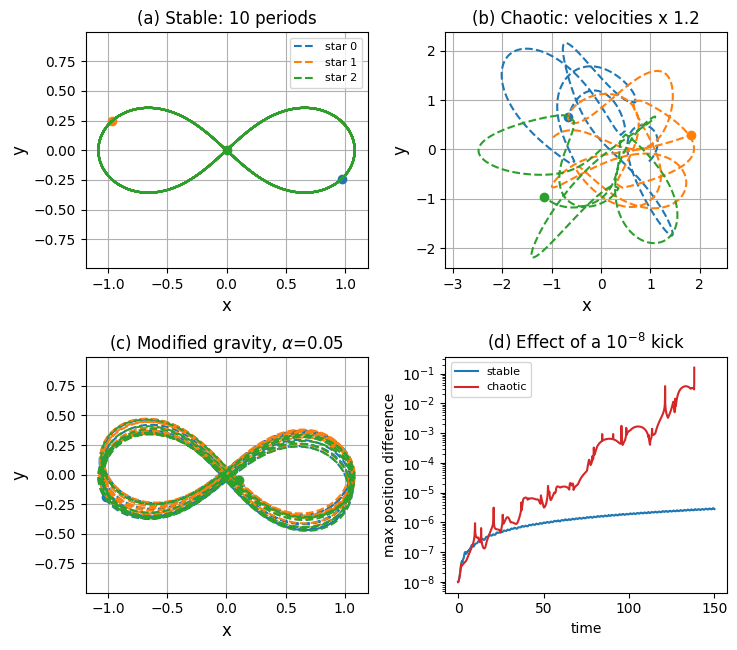

In [20]:
def max_position_difference(run_a, run_b):
    #biggest gap betweeen the same star in two runs
    n = min(run_a.y_solution.shape[1], run_b.y_solution.shape[1])
    xa, ya, _, _ = run_a.split_state(run_a.y_solution[:, :n])
    xb, yb, _, _ = run_b.split_state(run_b.y_solution[:, :n])
    return np.hypot(xa - xb, ya - yb).max(axis=0), run_a.t_solution[:n]


def solve_variant(max_time, velocity_scale=1.0, x_shift=0.0, lam=0.0):
    #Solve a figure-eight variant with modified gravity or sped up
    system = make_figure_eight(velocity_scale, x_shift, lam)
    system.solve_stellar_motion(max_time, n_steps=int(20 * max_time), tolerance=1e-12)
    return system


def divergence(velocity_scale):
    #Position difference vs time for an orbit and a copy.
    original = solve_variant(150, velocity_scale=velocity_scale)
    nudged = solve_variant(150, velocity_scale=velocity_scale, x_shift=1e-8)
    return max_position_difference(original, nudged)



velocity_chaoticness = 1.2    # velocity scale that makes the orbit chaotic, speeds up the stars by 20%
stable = solve_variant(10 * FIGURE_EIGHT_PERIOD)
chaotic = solve_variant(40, velocity_scale=velocity_chaoticness)
modified_orbit = solve_variant(40, lam=0.05)
stable_difference, stable_times  = divergence(1.0)
chaotic_difference, chaotic_times = divergence(velocity_chaoticness)

# a straight line on a log plot means exponential growth, so I fit the slope
growth_rate = np.polyfit(chaotic_times[200:2400], np.log(chaotic_difference[200:2400]), 1)[0]
print(f"Chaotic run grows as exp({growth_rate:.3f} t); e-folding time {1 / growth_rate:.1f}")
assert growth_rate > 0.03, "expected exponential divergence"

# ---- plot ------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(7.4, 6.6))
titles = ("(a) Stable: 10 periods", "(b) Chaotic: velocities x 1.2",
          "(c) Modified gravity, $\\alpha$=0.05")
for ax, system, title in zip(axes.flat, (stable, chaotic, modified_orbit),
                             titles):
    system.plot_the_orbits(ax, title=title, legend=(system is stable))
axes[1, 1].semilogy(stable_times, stable_difference, "C0", label="stable")
axes[1, 1].semilogy(chaotic_times, chaotic_difference, "C3", label="chaotic")
axes[1, 1].set(xlabel="time", ylabel="max position difference",
               title="(d) Effect of a $10^{-8}$ kick")
axes[1, 1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("fig_solutions.png", dpi=150, bbox_inches="tight")
plt.show()

# Validation
**With normal gravity, energy and momentum shouldn't change. If they change it is wrong.**

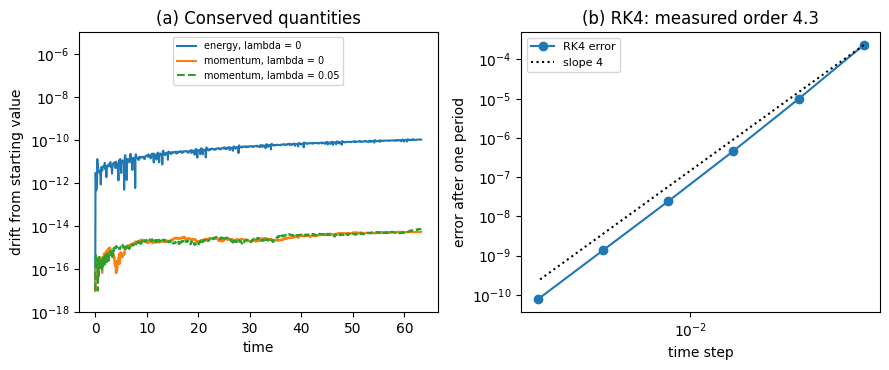

In [21]:
# run the figure eight for 10 periods with normal and modified gravity
newton = solve_variant(10 * FIGURE_EIGHT_PERIOD, lam=0.0)
modified = solve_variant(10 * FIGURE_EIGHT_PERIOD, lam=0.05)

# how much each quantity has drifted from its starting value
FLOOR = 1e-17   # stops log(0) from breaking the plot
energy = newton.calculate_total_energy(newton.y_solution)
energy_drift = np.abs(energy - energy[0]) + FLOOR
momentum_newton = newton.calculate_total_momentum(newton.y_solution) + FLOOR
momentum_modified = (modified.calculate_total_momentum(modified.y_solution)
                     + FLOOR)

# the line RK4 should follow if it is 4th order
slope_4_line = rk4_errors[0] * (delta_ts / delta_ts[0])**4

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.8))

# left; energy and momentum should stay constant
left.semilogy(newton.t_solution, energy_drift, label="energy, lambda = 0")
left.semilogy(newton.t_solution, momentum_newton,
              label="momentum, lambda = 0")
left.semilogy(modified.t_solution, momentum_modified, "--",
              label="momentum, lambda = 0.05")
left.set_xlabel("time")
left.set_ylabel("drift from starting value")
left.set_title("(a) Conserved quantities")
left.set_ylim(1e-18, 1e-5)
left.legend(fontsize=7, loc="upper center")

# right; RK4 error should fall with slope 4
right.loglog(delta_ts, rk4_errors, "o-", label="RK4 error")
right.loglog(delta_ts, slope_4_line, "k:", label="slope 4")
right.set_xlabel("time step")
right.set_ylabel("error after one period")
right.set_title(f"(b) RK4: measured order {rk4_order:.1f}")
right.minorticks_off()   # stops the x labels overlapping
right.legend(fontsize=8)

plt.tight_layout()
plt.savefig("fig_validation.png", dpi=150, bbox_inches="tight")
plt.show()

lambda = 0.0 : orbit is okay
lambda = 0.02 : orbit is okay
lambda = 0.05 : orbit is okay


/var/folders/2y/vy4bcrl902180bzn1kl9dk1m0000gn/T/ipykernel_30098/97958880.py:84: UserWarning: Close encounter (< 0.001) at t = 45.939; stopped early.
  warnings.warn(f"Close encounter (< {min_separation}) at "
/var/folders/2y/vy4bcrl902180bzn1kl9dk1m0000gn/T/ipykernel_30098/97958880.py:84: UserWarning: Close encounter (< 0.001) at t = 1.891; stopped early.
  warnings.warn(f"Close encounter (< {min_separation}) at "


lambda = 0.1 : stars collided at t = 45.9
lambda = 0.15 : stars collided at t = 1.9


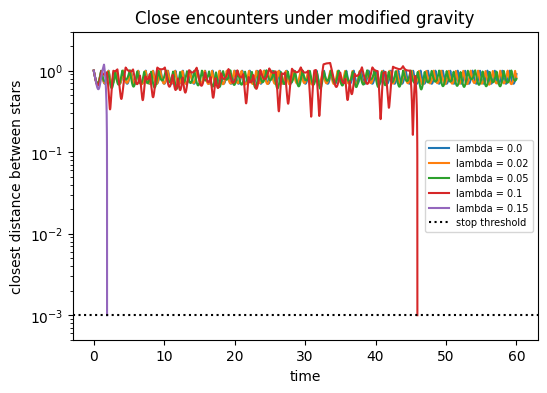

In [22]:
lambdas = [0.0, 0.02, 0.05, 0.1, 0.15]
end_time = 60.0

plt.figure(figsize=(6, 4))

for lam in lambdas:
    system = make_figure_eight(lam=lam)
    system.solve_stellar_motion(end_time, n_steps=6000, tolerance=1e-10)

    # smallest distance between any two stars at each time
    separations = system.calculate_pair_separations(system.y_solution)
    closest = separations.min(axis=0)

    plt.semilogy(system.t_solution, closest, label="lambda = " + str(lam))

    # if the solver stopped before end time, two stars got too close
    if system.t_solution[-1] < end_time:
        print("lambda =", lam, ": stars collided at t =", round(system.t_solution[-1], 1))
    else:
        print("lambda =", lam, ": orbit is okay")

plt.axhline(MINIMUM_SEPARATION, color="black", linestyle=":", label="stop threshold")
plt.xlabel("time")
plt.ylabel("closest distance between stars")
plt.title("Close encounters under modified gravity")
plt.ylim(5e-4, 3.0)
plt.legend(fontsize=7)
plt.savefig("fig_encounters.png", dpi=150)
plt.show()

# **Building your own system (for ESA colleagues)**
# Change this cell form mark down to code and choose masses , positions ,name of the star and velocities as you wish.
my_system = StarSystem(lam=0.0)
my_system.add_star(Star(-1.0, 0.0, 0.0, -0.3, mass=1.0, name="Star1"))
my_system.add_star(Star(1.0, 0.0, 0.0, 0.6, mass=0.5, name="Star2"))
my_system.add_star(Star(0.0, 2.0, 0.0, 0.0, mass=0.2, name="Star3"))
my_system.solve_stellar_motion(20.0)
my_system.plot_the_orbits(title="A custom three-star system")
plt.show()